BÀI 3: MNIST với k-fold cross validation (k = 10)

Cell 0: Import thư viện

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

Câu a) Đọc bộ dữ liệu train, test của MNIST từ Keras

In [2]:
print("Lê Anh Pha - 6451071056")

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
print("Đã đọc xong bộ dữ liệu MNIST")

Lê Anh Pha - 6451071056
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Đã đọc xong bộ dữ liệu MNIST


Câu b) In ra kích thước của tập train, test

In [3]:
print("Lê Anh Pha - 6451071056")

print("train_images:", train_images.shape)
print("train_labels:", train_labels.shape)
print("test_images :", test_images.shape)
print("test_labels :", test_labels.shape)

Lê Anh Pha - 6451071056
train_images: (60000, 28, 28)
train_labels: (60000,)
test_images : (10000, 28, 28)
test_labels : (10000,)


Câu c) Chuẩn hóa các giá trị pixel về đoạn [0,1]

In [4]:
print("Lê Anh Pha - 6451071056")

print("Trước chuẩn hóa: min =", train_images.min(), "| max =", train_images.max())

train_images = train_images / 255.0
test_images = test_images / 255.0

print("Sau chuẩn hóa : min =", train_images.min(), "| max =", train_images.max())

Lê Anh Pha - 6451071056
Trước chuẩn hóa: min = 0 | max = 255
Sau chuẩn hóa : min = 0.0 | max = 1.0


Câu d) Định nghĩa hàm create_model

In [5]:
print("Lê Anh Pha - 6451071056")

def create_model():
    model = Sequential([
        Input(shape=(28, 28)),
        Flatten(),                        # 28x28 -> vector 784 chiều
        Dense(128, activation='relu'),    # fully connected, 128 neuron
        Dropout(0.2),                     # tắt ngẫu nhiên 20% neuron khi huấn luyện
        Dense(10, activation='softmax')   # 10 lớp (chữ số 0-9)
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Tạo thử 1 mô hình để xem cấu trúc
create_model().summary()

Lê Anh Pha - 6451071056


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Câu e) Huấn luyện bằng k-fold cross validation (k = 10)

In [6]:
print("Lê Anh Pha - 6451071056")

kfold = KFold(n_splits=10, shuffle=True, random_state=42)

models = []
accuracy_per_fold = []
loss_per_fold = []

fold_no = 1
for train_index, val_index in kfold.split(train_images):
    print(f"\n========== Fold {fold_no}/10 ==========")

    model = create_model()

    X_train_fold, X_val_fold = train_images[train_index], train_images[val_index]
    y_train_fold, y_val_fold = train_labels[train_index], train_labels[val_index]

    model.fit(X_train_fold, y_train_fold,
              validation_data=(X_val_fold, y_val_fold),
              epochs=5, batch_size=32, verbose=1)

    # Lưu mô hình sau mỗi fold
    models.append(model)

    # Tính loss và accuracy của fold trên tập validation của fold đó
    loss, acc = model.evaluate(X_val_fold, y_val_fold, verbose=0)
    loss_per_fold.append(loss)
    accuracy_per_fold.append(acc)
    print(f"Fold {fold_no}: loss = {loss:.4f} | accuracy = {acc:.4f}")

    fold_no += 1

Lê Anh Pha - 6451071056

========== Fold 1/10 ==========
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9101 - loss: 0.3120 - val_accuracy: 0.9552 - val_loss: 0.1564
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9552 - loss: 0.1501 - val_accuracy: 0.9682 - val_loss: 0.1073
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9671 - loss: 0.1101 - val_accuracy: 0.9743 - val_loss: 0.0866
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9717 - loss: 0.0915 - val_accuracy: 0.9762 - val_loss: 0.0778
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9764 - loss: 0.0766 - val_accuracy: 0.9763 - val_loss: 0.0729
Fold 1: loss = 0.0729 | accuracy = 0.9763

========== Fold 2/10 ==========
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9081 - loss: 0.3118 - val_accuracy: 0.9548 - val_loss: 0.1627
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9555 - loss: 0.1499 - v

Câu f) Mean Accuracy, Std Accuracy, Mean Loss, Std Loss

In [7]:
print("Lê Anh Pha - 6451071056")

print(f"Mean Accuracy              : {np.mean(accuracy_per_fold):.4f}")
print(f"Standard deviation accuracy: {np.std(accuracy_per_fold):.4f}")
print(f"Mean Loss                  : {np.mean(loss_per_fold):.4f}")
print(f"Standard deviation loss    : {np.std(loss_per_fold):.4f}")

Lê Anh Pha - 6451071056
Mean Accuracy              : 0.9738
Standard deviation accuracy: 0.0030
Mean Loss                  : 0.0858
Standard deviation loss    : 0.0094


Câu g) Vẽ biểu đồ accuracy, loss sau mỗi fold

Lê Anh Pha - 6451071056


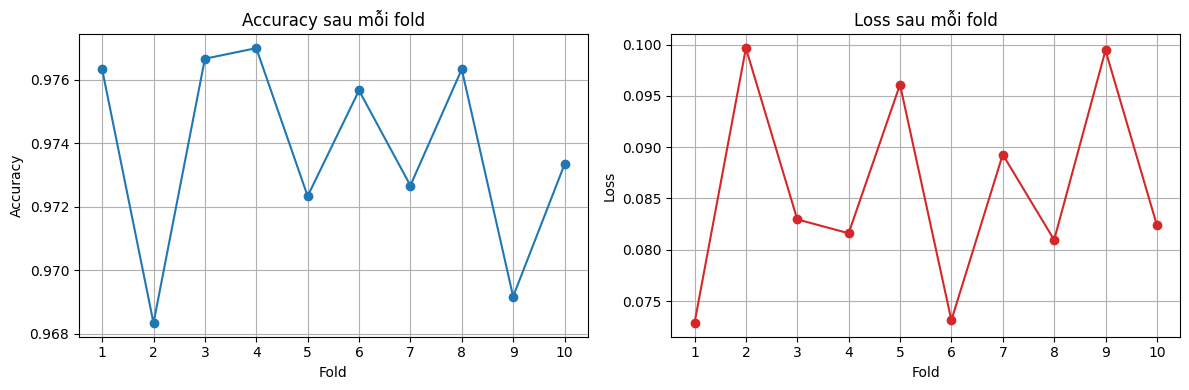

In [8]:
print("Lê Anh Pha - 6451071056")

folds = range(1, 11)

plt.figure(figsize=(12, 4))

# Biểu đồ accuracy
plt.subplot(1, 2, 1)
plt.plot(folds, accuracy_per_fold, marker='o', color='tab:blue')
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.title('Accuracy sau mỗi fold')
plt.xticks(folds)
plt.grid(True)

# Biểu đồ loss
plt.subplot(1, 2, 2)
plt.plot(folds, loss_per_fold, marker='o', color='tab:red')
plt.xlabel('Fold')
plt.ylabel('Loss')
plt.title('Loss sau mỗi fold')
plt.xticks(folds)
plt.grid(True)

plt.tight_layout()
plt.show()

Câu h) Dùng mô hình có Accuracy tốt nhất để phân lớp tập test

In [9]:
print("Lê Anh Pha - 6451071056")

best_index = np.argmax(accuracy_per_fold)
best_model = models[best_index]
print(f"Mô hình tốt nhất: Fold {best_index + 1} với accuracy = {accuracy_per_fold[best_index]:.4f}")

y_prob = best_model.predict(test_images)   # xác suất từng lớp
y_pred = np.argmax(y_prob, axis=1)         # chọn lớp có xác suất lớn nhất

print("Kích thước ma trận xác suất:", y_prob.shape)
print("10 nhãn dự đoán đầu tiên:", y_pred[:10])
print("10 nhãn thực tế đầu tiên:", test_labels[:10])

Lê Anh Pha - 6451071056
Mô hình tốt nhất: Fold 4 với accuracy = 0.9770
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Kích thước ma trận xác suất: (10000, 10)
10 nhãn dự đoán đầu tiên: [7 2 1 0 4 1 4 9 5 9]
10 nhãn thực tế đầu tiên: [7 2 1 0 4 1 4 9 5 9]


Câu i) Accuracy trên tập test

In [10]:
print("Lê Anh Pha - 6451071056")

acc = accuracy_score(test_labels, y_pred)
print("Accuracy trên tập test:", acc)
print(f"Accuracy trên tập test: {acc*100:.2f}%")

Lê Anh Pha - 6451071056
Accuracy trên tập test: 0.977
Accuracy trên tập test: 97.70%


Câu j) Precision, Recall, F1-score từng lớp và trung bình

In [11]:
print("Lê Anh Pha - 6451071056")

print(classification_report(test_labels, y_pred, digits=4))

Lê Anh Pha - 6451071056
              precision    recall  f1-score   support

           0     0.9740    0.9939    0.9838       980
           1     0.9834    0.9903    0.9868      1135
           2     0.9710    0.9738    0.9724      1032
           3     0.9715    0.9782    0.9748      1010
           4     0.9766    0.9786    0.9776       982
           5     0.9754    0.9776    0.9765       892
           6     0.9822    0.9770    0.9796       958
           7     0.9774    0.9669    0.9721      1028
           8     0.9793    0.9713    0.9753       974
           9     0.9788    0.9613    0.9700      1009

    accuracy                         0.9770     10000
   macro avg     0.9770    0.9769    0.9769     10000
weighted avg     0.9770    0.9770    0.9770     10000



Câu k) Confusion matrix bằng heatmap

Lê Anh Pha - 6451071056


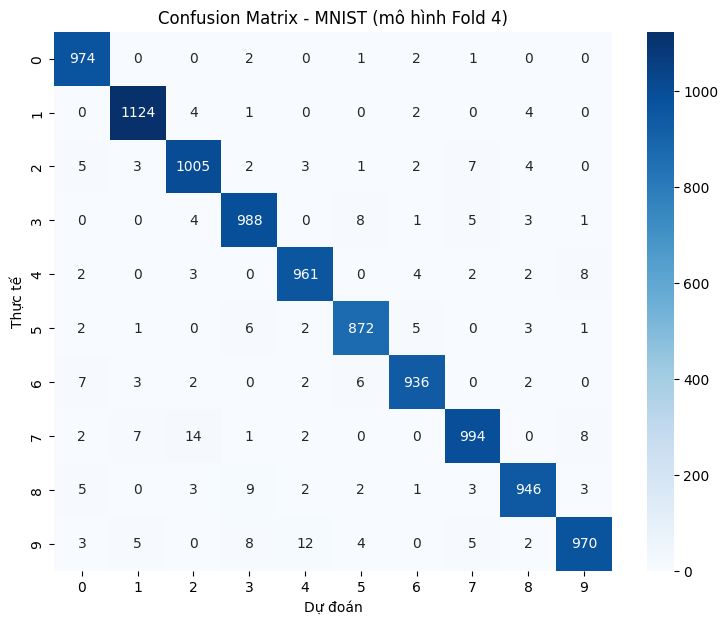

In [12]:
print("Lê Anh Pha - 6451071056")

cm = confusion_matrix(test_labels, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.title(f'Confusion Matrix - MNIST (mô hình Fold {best_index + 1})')
plt.show()

Câu l) Kết quả phân lớp của 05 ảnh đầu tiên trong tập test

Lê Anh Pha - 6451071056


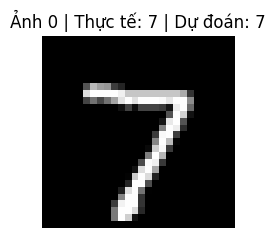

Ảnh 0: nhãn thực tế = 7, nhãn dự đoán = 7


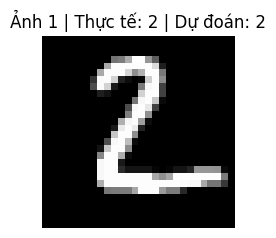

Ảnh 1: nhãn thực tế = 2, nhãn dự đoán = 2


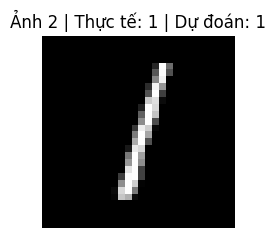

Ảnh 2: nhãn thực tế = 1, nhãn dự đoán = 1


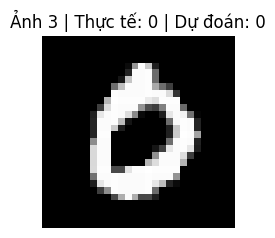

Ảnh 3: nhãn thực tế = 0, nhãn dự đoán = 0


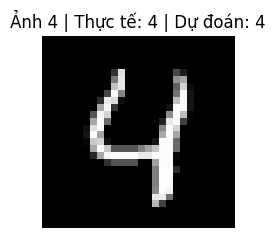

Ảnh 4: nhãn thực tế = 4, nhãn dự đoán = 4


In [13]:
print("Lê Anh Pha - 6451071056")

for image_index in range(5):
    # expand_dims: (28,28) -> (1,28,28) để đưa vào mô hình
    image = np.expand_dims(test_images[image_index], axis=0)
    prediction = best_model.predict(image, verbose=0)
    predicted_label = np.argmax(prediction)

    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(test_images[image_index], cmap='gray')
    plt.title(f"Ảnh {image_index} | Thực tế: {test_labels[image_index]} | Dự đoán: {predicted_label}")
    plt.axis('off')
    plt.show()

    print(f"Ảnh {image_index}: nhãn thực tế = {test_labels[image_index]}, nhãn dự đoán = {predicted_label}")